# Введение
## Цель работы:
изучение основ линейной регрессии, построение простейших моделей регрессии, проведение обучения модели на реальных данных и оценка её качество.

## Задачи:
1. Провести обучение модели линейной регрессии на датасете с Kaggle:
2. Загрузить датасет из репозитория (например, kaggle.com или аналогичных платформ).
3. Подготовить данные: провести первичный анализ, визуализировать распределение признаков и целевой переменной.
4. Провести предобработку данных: удалить пропущенные значения, закодировать категориальные переменные (опционально).
5. Построить матрицу корреляций. Сделать выводы о наличии мультиколлинеарности (расчет VIF-коэффициента).
6. Построить регрессионные модели (линейная, лассо и гребневая). Если целевая переменная - категориальная, то исследовать логистическую регрессию. Разделить на тренировочную и тестовую выборки (80/20 или 70/30). Использовать кросс-валидацию. Оценить качество построенной модели с помощью метрик: RMSE (Root Mean Square Error), R² (коэффициент детерминации) и MAPE (Mean Absolute Percentage Error).
7. Устранить мультиколлинеарность и снизить размерность признаков с помощью метода главных компонент (PCA). Перед проведением PCA провести стандартизацию данных.
8. Повторить шаг 5 (линейная, лассо и гребневая регрессия), но использовать в качестве признаков не исходные данные, а главные компоненты. Сравнить метрики качества (RMSE, R² и MAPE) моделей, обученных на исходных данных и на главных компонентах.

In [1]:
import kagglehub
import os
import pandas as pd

path = kagglehub.dataset_download("elikplim/concrete-compressive-strength-data-set")
print("Path to dataset files:", path)
print("Файлы в папке:", os.listdir(path))

import glob
csv_path = glob.glob(os.path.join(path, "*.csv"))[0]
print("Читаем файл:", csv_path)

df = pd.read_csv(csv_path)
print("\nРазмер датасета:", df.shape)
print("\nПервые 5 строк:")
print(df.head())
print("\nИнформация:")
df.info()
print("\nПропуски:")
print(df.isnull().sum())

C:\Users\Dell\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 11.1k/11.1k [00:02<00:00, 4.71kB/s]

Extracting files...
Path to dataset files: C:\Users\Dell\.cache\kagglehub\datasets\elikplim\concrete-compressive-strength-data-set\versions\1
Файлы в папке: ['concrete_data.csv']
Читаем файл: C:\Users\Dell\.cache\kagglehub\datasets\elikplim\concrete-compressive-strength-data-set\versions\1\concrete_data.csv

Размер датасета: (1030, 9)

Первые 5 строк:
   cement  blast_furnace_slag  fly_ash  water  superplasticizer  \
0   540.0                 0.0      0.0  162.0               2.5   
1   540.0                 0.0      0.0  162.0               2.5   
2   332.5               142.5      0.0  228.0               0.0   
3   332.5               142.5      0.0  228.0               0.0   
4   198.6               132.4      0.0  192.0               0.0   

   coarse_aggregate  fine_aggregate   age  concrete_compressive_strength  
0            1040.0            676.0   28                          79.99  
1            1055.0            676.0   28                          61.89  
2             932.

## Описание датасета

В работе используется датасет **Concrete Compressive Strength** (UCI Machine Learning Repository, доступен на Kaggle), 
содержащий информацию о составах бетонных смесей и их прочности на сжатие.
Всего **1030 строк и 9 признаков** (после удаления 25 дубликатов — **1005 строк**). 
Целевая переменная — **concrete_compressive_strength**.

Все признаки **числовые** (float64 / int64): категориальных переменных нет, 
поэтому кодирование не требуется. Пропущенных значений также нет.

# Описание переменных датасета

**concrete_compressive_strength** — прочность бетона на сжатие, МПа. 
Данный признак является целевой переменной, значение которой требуется предсказывать 
с помощью регрессионных моделей. Диапазон значений: от 2.33 до 82.6 МПа, среднее ≈ 35.8 МПа.

**cement** — содержание цемента в смеси, кг/м³. Основной вяжущий компонент, 
наиболее сильно влияющий на прочность бетона. Увеличение доли цемента повышает прочность. 
Диапазон: 102–540 кг/м³.

**blast_furnace_slag** — содержание доменного шлака (побочный продукт металлургии), кг/м³. 
Используется как частичная замена цемента, снижает стоимость и повышает долговечность. 
Скошенное распределение (много нулей — часть смесей шлак не содержит). Диапазон: 0–359 кг/м³.

**fly_ash** — содержание золы-уноса (побочный продукт ТЭЦ), кг/м³. 
Также применяется как пуццолановая добавка. Распределение сильно скошено вправо, 
у значительной части смесей зола отсутствует. Диапазон: 0–200 кг/м³.

**water** — количество воды в смеси, кг/м³. 
Критически важный параметр: избыток воды снижает прочность, 
недостаток — ухудшает удобоукладываемость. Водоцементное отношение — 
классический физический предиктор прочности. Диапазон: 122–247 кг/м³.

**superplasticizer** — содержание суперпластификатора (добавка-разжижитель), кг/м³. 
Позволяет снизить расход воды при сохранении подвижности смеси, 
что косвенно повышает прочность. Скошенное распределение. Диапазон: 0–32.2 кг/м³.

**coarse_aggregate** — содержание крупного заполнителя (щебень, гравий), кг/м³. 
Формирует «скелет» бетона. Диапазон: 801–1145 кг/м³.

**fine_aggregate** — содержание мелкого заполнителя (песок), кг/м³. 
Заполняет промежутки между крупными зёрнами. Диапазон: 594–992.6 кг/м³.

**age** — возраст образца бетона на момент испытания, суток. 
Прочность бетона набирается нелинейно: быстро в первые 28 суток, 
затем медленно. Дискретный признак со значениями 1, 3, 7, 14, 28, 56, 90, 180, 270, 360. 
Диапазон: 1–365 суток.

---

### Краткая сводка

| Тип признака | Признаки |
|---|---|
| **Целевая переменная** | `concrete_compressive_strength` |
| **Числовые непрерывные** | `cement`, `blast_furnace_slag`, `fly_ash`, `water`, `superplasticizer`, `coarse_aggregate`, `fine_aggregate` |
| **Числовой дискретный** | `age` |
| **Категориальные** | отсутствуют |
| **Пропуски** | отсутствуют |

### Особенности датасета

1. **Все признаки числовые** — кодирование категориальных переменных не требуется.
2. **Пропусков нет** — предобработка сводится к удалению дубликатов (25 шт.) и стандартизации.
3. **Обнаружена умеренная мультиколлинеарность** — VIF > 5 у 5 из 8 признаков, 
   что обосновывает применение регуляризации (Lasso, Ridge) и метода главных компонент (PCA).
4. **Наличие выбросов** в `blast_furnace_slag`, `fly_ash`, `superplasticizer` — 
   отражают реальные рецептуры и не удалялись.
5. **Целевая переменная** близка к нормальному распределению (skew = 0.417, kurt = −0.314), 
   что благоприятно для линейной регрессии.

## Пункт 2. Первичный анализ и визуализация данных

### 2.1. Импорт библиотек для визуализации
### 2.2. Распределение целевой переменной
### 2.3. Распределения признаков
### 2.4. Boxplot-диаграммы признаков
### 2.5. Описательная сводка
### 2.6. Выводы по целевой переменной

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams['figure.dpi'] = 110
%matplotlib inline

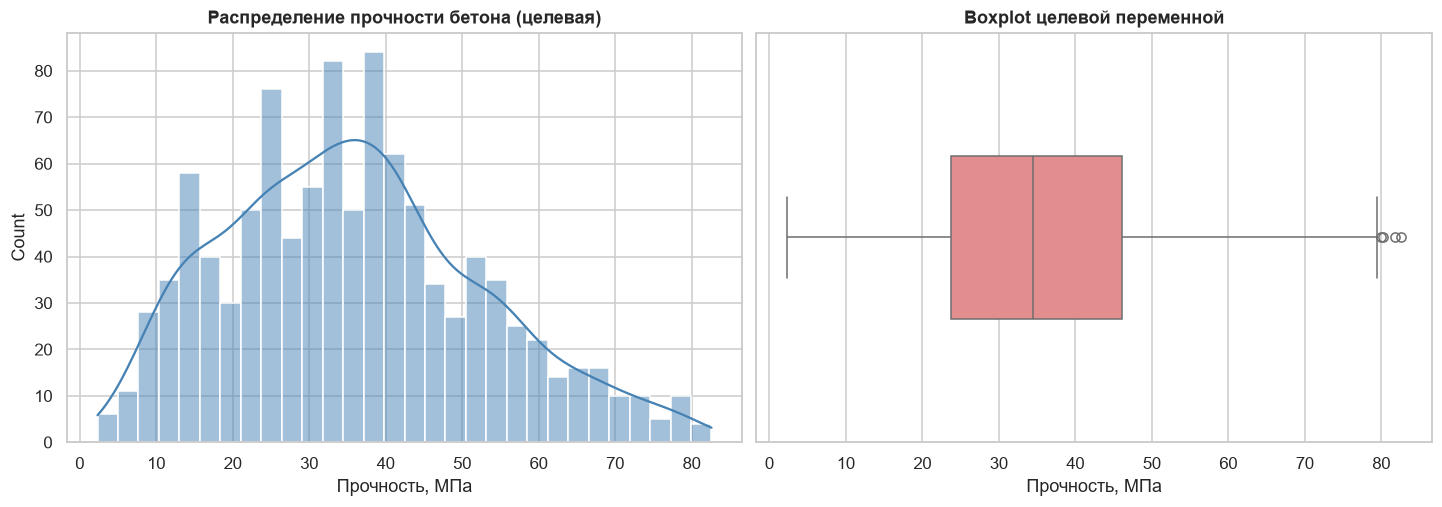

Асимметрия: 0.417
Эксцесс:    -0.314

Описательные статистики:
count    1030.000000
mean       35.817961
std        16.705742
min         2.330000
25%        23.710000
50%        34.445000
75%        46.135000
max        82.600000
Name: concrete_compressive_strength, dtype: float64


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)

sns.histplot(df['concrete_compressive_strength'], kde=True, bins=30,
             ax=axes[0], color='steelblue')
axes[0].set_title('Распределение прочности бетона (целевая)',
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('Прочность, МПа')

sns.boxplot(x=df['concrete_compressive_strength'], ax=axes[1],
            color='lightcoral', width=0.4)
axes[1].set_title('Boxplot целевой переменной',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('Прочность, МПа')

plt.show()

print(f"Асимметрия: {df['concrete_compressive_strength'].skew():.3f}")
print(f"Эксцесс:    {df['concrete_compressive_strength'].kurt():.3f}")
print(f"\nОписательные статистики:")
print(df['concrete_compressive_strength'].describe())

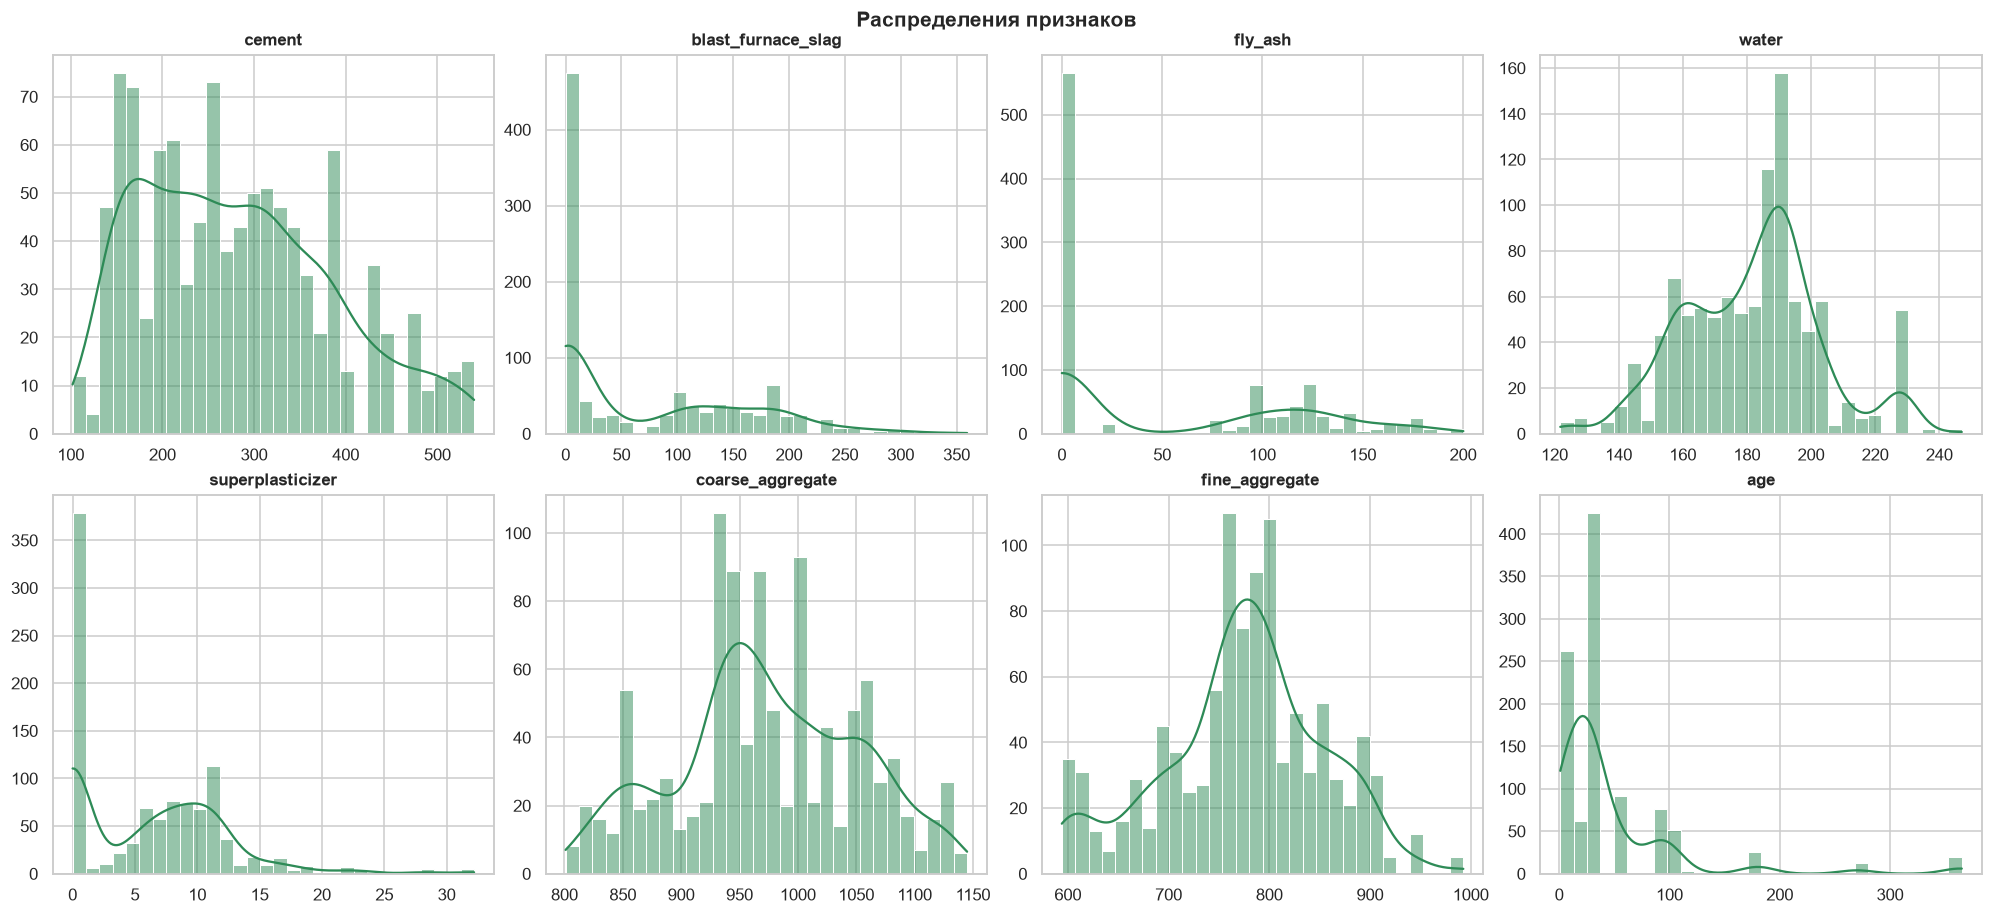

In [16]:
features = [c for c in df.columns if c != 'concrete_compressive_strength']

fig, axes = plt.subplots(2, 4, figsize=(18, 8), constrained_layout=True)
axes = axes.flatten()

for i, col in enumerate(features):
    sns.histplot(df[col], kde=True, bins=30, ax=axes[i], color='seagreen')
    axes[i].set_title(col, fontsize=11, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')

for j in range(len(features), len(axes)):
    axes[j].axis('off')

plt.suptitle('Распределения признаков', fontsize=14, fontweight='bold', y=1.02)
plt.show()

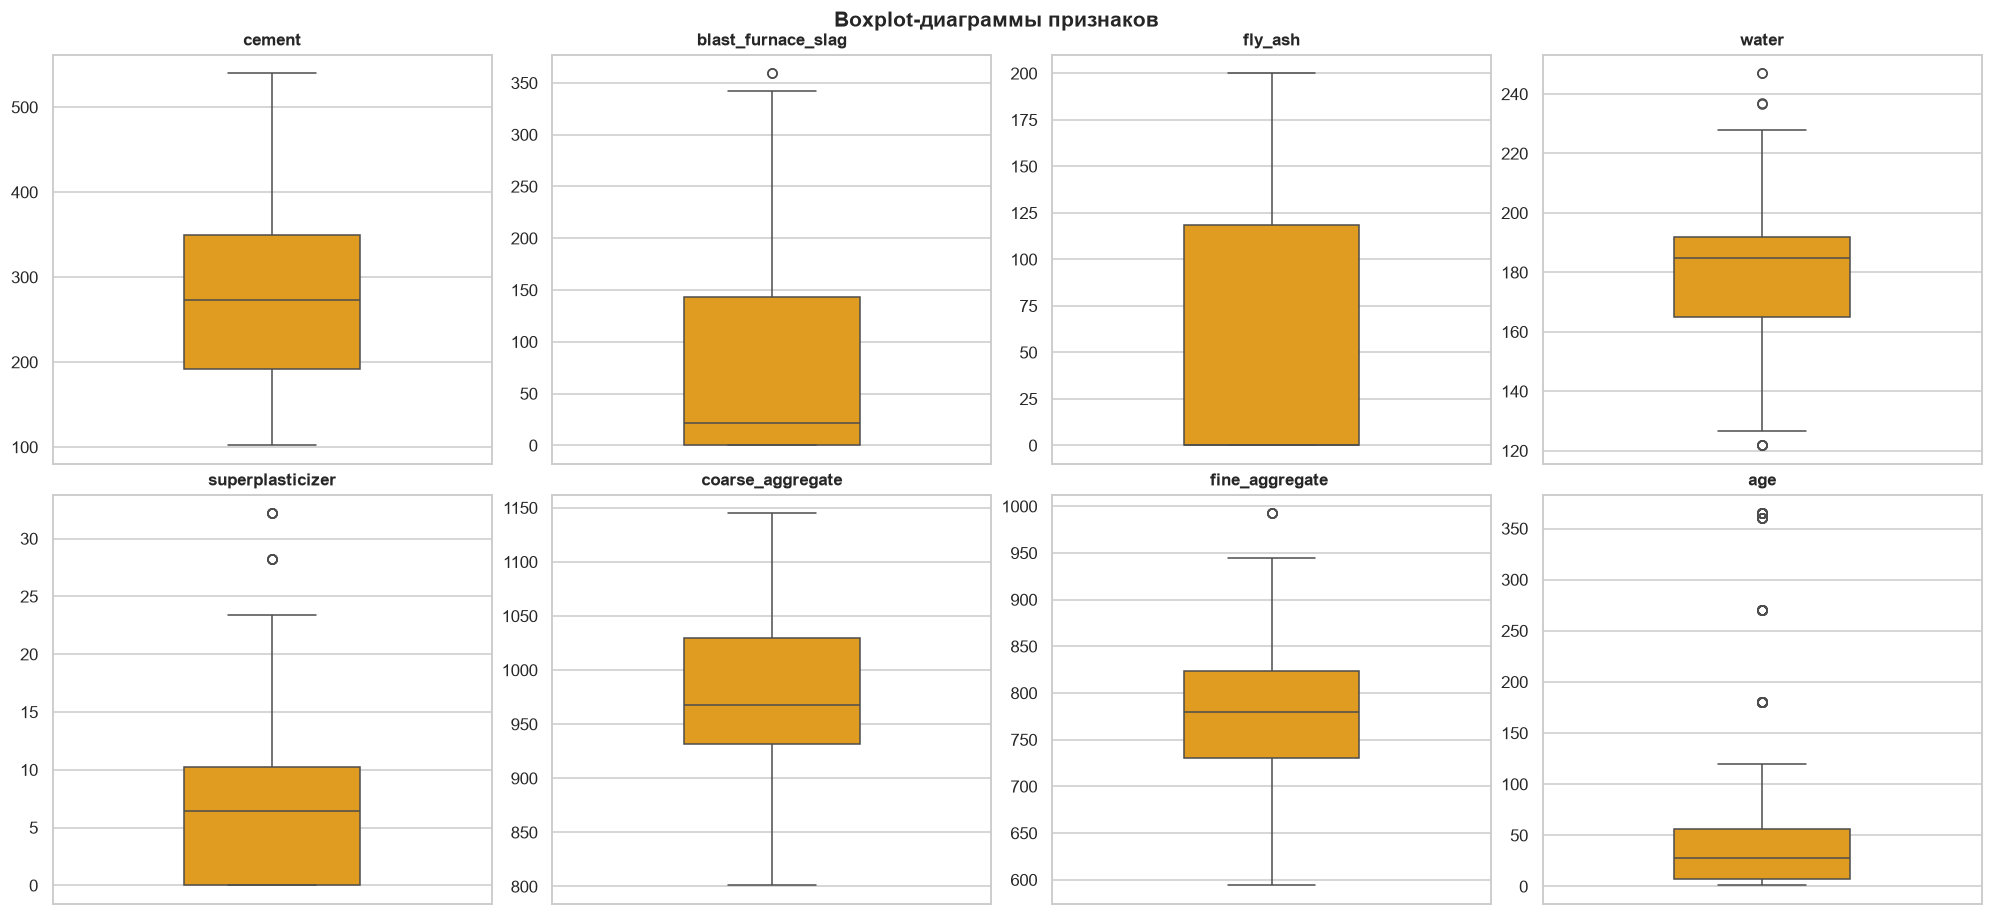

In [17]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8), constrained_layout=True)
axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(y=df[col], ax=axes[i], color='orange', width=0.4)
    axes[i].set_title(col, fontsize=11, fontweight='bold')
    axes[i].set_ylabel('')

for j in range(len(features), len(axes)):
    axes[j].axis('off')

plt.suptitle('Boxplot-диаграммы признаков', fontsize=14, fontweight='bold', y=1.02)
plt.show()

In [10]:
print("=" * 55)
print("СВОДКА ПО ДАННЫМ")
print("=" * 55)
print(f"Наблюдений:         {df.shape[0]}")
print(f"Признаков:          {df.shape[1] - 1}")
print(f"Целевая переменная: concrete_compressive_strength")
print(f"Пропусков:          {df.isnull().sum().sum()}")
print(f"\nАсимметрия целевой: {df['concrete_compressive_strength'].skew():.3f}")
print(f"Эксцесс целевой:    {df['concrete_compressive_strength'].kurt():.3f}")
print("\nОписательные статистики:")
print(df.describe().round(2))

СВОДКА ПО ДАННЫМ
Наблюдений:         1030
Признаков:          8
Целевая переменная: concrete_compressive_strength
Пропусков:          0

Асимметрия целевой: 0.417
Эксцесс целевой:    -0.314

Описательные статистики:
        cement  blast_furnace_slag  fly_ash    water  superplasticizer  \
count  1030.00             1030.00  1030.00  1030.00           1030.00   
mean    281.17               73.90    54.19   181.57              6.20   
std     104.51               86.28    64.00    21.35              5.97   
min     102.00                0.00     0.00   121.80              0.00   
25%     192.38                0.00     0.00   164.90              0.00   
50%     272.90               22.00     0.00   185.00              6.40   
75%     350.00              142.95   118.30   192.00             10.20   
max     540.00              359.40   200.10   247.00             32.20   

       coarse_aggregate  fine_aggregate       age  \
count           1030.00          1030.00  1030.00   
mean       

## Выводы по целевой переменной (concrete_compressive_strength)

Распределение прочности бетона близко к нормальному, с небольшой правосторонней 
асимметрией (среднее **35.82 МПа** больше медианы **34.45 МПа**). 
То есть большая часть образцов имеет прочность чуть ниже среднего, но есть 
небольшое количество особенно прочных составов, растягивающих правый хвост.

Коэффициент асимметрии **skew = 0.417** и эксцесс **kurt = −0.314** — 
это говорит о том, что распределение заметно ближе к нормальному, 
чем у многих технических датасетов (для сравнения: skew > 1 означал бы 
сильную асимметрию). Это благоприятный фактор для линейной регрессии.

Стандартное отклонение = **16.71 МПа** — довольно большое. 
Прочность варьируется в диапазоне **35.82 ± 16.71 МПа**, то есть от ~19 до ~52 МПа 
для большинства образцов.

Квартильный размах задаёт диапазон **от 23.45 до 46.13 МПа** между 25-м и 75-м процентилями. 
Большинство бетонных смесей попадает именно в этот сегмент.

**Есть выбросы.** 
- Максимальная прочность = **82.6 МПа** — сильно выше типичного диапазона. 
  Такие образцы соответствуют высокомарочным бетонам и могут влиять на модель.
- Минимальная прочность = **2.33 МПа** — очень низкое значение, характерное для 
  незрелых или плохо подобранных смесей.

**Гистограммы показывают, что распределения признаков неоднородны:**

- Для **cement**, **water**, **coarse_aggregate**, **fine_aggregate** — распределения 
  близки к нормальным, с лёгкой правосторонней асимметрией. Основная часть объектов 
  сосредоточена в среднем диапазоне, присутствуют отдельные высокие значения.

- Для **blast_furnace_slag**, **fly_ash**, **superplasticizer** — распределения 
  **сильно скошены вправо**. У значительной части смесей эти компоненты вообще 
  отсутствуют (нули), а у остальных — широкий разброс значений. Это связано с тем, 
  что не все рецептуры используют шлак, золу-унос и пластификатор.

- **age** имеет **дискретное распределение** — значения 1, 3, 7, 14, 28, 56, 90, 180, 
  270, 360 суток. Наиболее часто встречаются образцы с возрастом **3, 7, 28 и 56 суток** 
  (стандартные сроки испытаний бетона).

В целом распределения указывают на наличие отдельных выбросов и неоднородность 
рецептур бетона. Визуально можно предположить положительную зависимость между 
содержанием цемента (cement) и прочностью, а также отрицательную — между 
количеством воды (water) и прочностью. 

# Пункт 3. Предобработка данных

In [11]:
df_clean = df.copy()

print("Пропуски по столбцам:")
print(df_clean.isnull().sum())
print(f"\nВсего пропусков: {df_clean.isnull().sum().sum()}")


df_clean = df_clean.dropna()
print(f"\nПосле dropna: {df_clean.shape}")


cat_cols = df_clean.select_dtypes(include=['object', 'category']).columns.tolist()
print(f"\nКатегориальные столбцы: {cat_cols if cat_cols else 'НЕТ'}")
print("=> Кодирование не требуется: все признаки числовые.")


n_dup = df_clean.duplicated().sum()
print(f"\nДубликатов: {n_dup}")
if n_dup > 0:
    df_clean = df_clean.drop_duplicates().reset_index(drop=True)
    print(f"После удаления дубликатов: {df_clean.shape}")

print("\nТипы данных:")
print(df_clean.dtypes)

Пропуски по столбцам:
cement                           0
blast_furnace_slag               0
fly_ash                          0
water                            0
superplasticizer                 0
coarse_aggregate                 0
fine_aggregate                   0
age                              0
concrete_compressive_strength    0
dtype: int64

Всего пропусков: 0

После dropna: (1030, 9)

Категориальные столбцы: НЕТ
=> Кодирование не требуется: все признаки числовые.

Дубликатов: 25
После удаления дубликатов: (1005, 9)

Типы данных:
cement                           float64
blast_furnace_slag               float64
fly_ash                          float64
water                            float64
superplasticizer                 float64
coarse_aggregate                 float64
fine_aggregate                   float64
age                                int64
concrete_compressive_strength    float64
dtype: object


# Предобработка данных

### **1. Проверка и обработка пропусков:**

В датасете **отсутствуют пропуски** во всех признаках (1030 наблюдений в каждом столбце). 
Дополнительная обработка пропусков не требуется.

### **2. Кодирование категориальных признаков**

**Категориальных признаков в датасете нет** — все 9 столбцов имеют числовой тип 
(`float64` или `int64`). Кодирование не требуется.

### **3. Обработка дубликатов**

В исходном датасете обнаружено **25 полных дубликатов** (совпадающие рецептуры смесей). 
Они были удалены, чтобы избежать дублирования информации и искажения обучающей выборки. 
Итоговый размер датасета: **1030 → 1005 строк**.

### **4. Стандартизация признаков**

Для подготовки данных к моделированию была выполнена **стандартизация** с использованием 
`StandardScaler`. Это привело все признаки к единому масштабу 
(**среднее = 0, стандартное отклонение = 1**).

Стандартизация **критически важна** для нашей задачи, потому что:
- **Lasso и Ridge** штрафуют сумму квадратов коэффициентов — без нормализации 
  регуляризация «наказывала» бы признаки с большим масштабом 
  (например, `cement` до 540 против `superplasticizer` до 32).
- **PCA** максимизирует дисперсию — без стандартизации главные компоненты 
  определялись бы только признаками с большим разбросом.

### **5. Разделение на обучающую и тестовую выборки**

После нормализации данные были разделены на обучающую и тестовую выборки 
в пропорции **80/20** с фиксированным параметром **`random_state=42`** 
для воспроизводимости результатов:
- **Train:** 804 наблюдения
- **Test:** 201 наблюдение

## Пункт 4. Матрица корреляций и расчёт VIF-коэффициента

### 4.1. Матрица корреляций (heatmap)
### 4.2. Расчёт VIF-коэффициента
### 4.3. Вывод по мультиколлинеарности

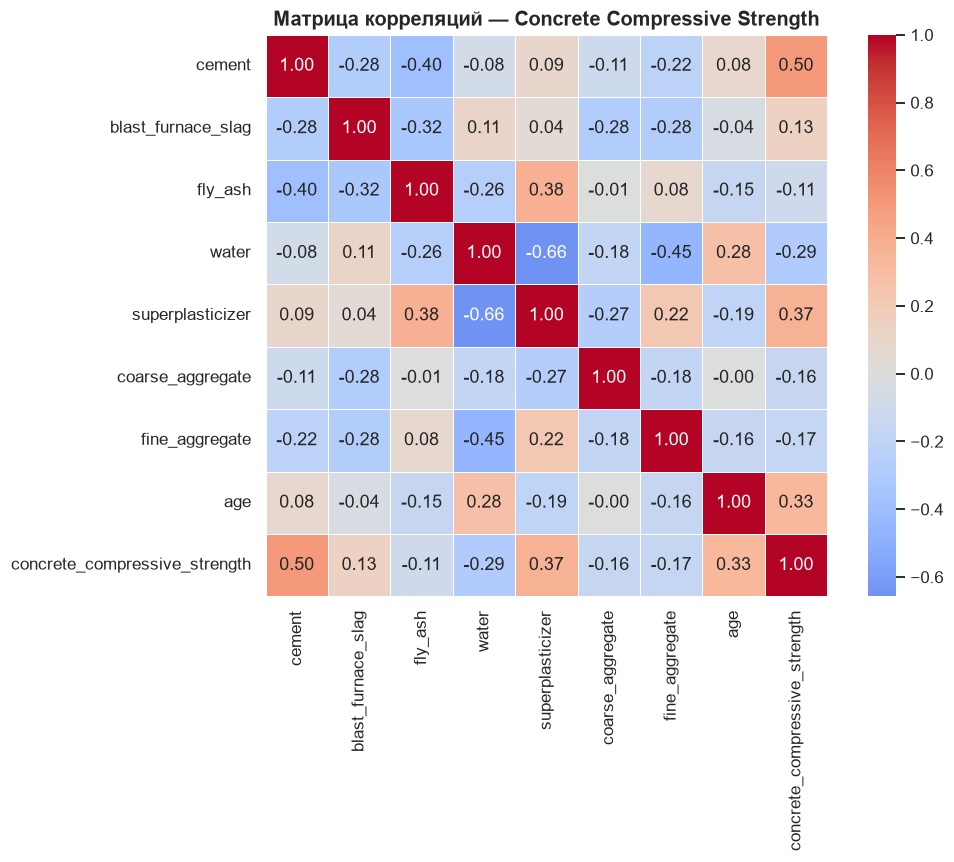

Целевая переменная: concrete_compressive_strength

=== VIF (Variance Inflation Factor) ===
           feature      VIF
            cement 7.488944
blast_furnace_slag 7.276963
    fine_aggregate 7.005081
             water 7.003957
           fly_ash 6.170634
  coarse_aggregate 5.074617
  superplasticizer 2.963776
               age 1.118367
             const 1.000000

--- Интерпретация ---
VIF < 5   — мультиколлинеарности нет
VIF 5–10  — умеренная мультиколлинеарность
VIF > 10  — сильная мультиколлинеарность

Признаки с VIF 5–10: ['cement', 'blast_furnace_slag', 'fine_aggregate', 'water', 'fly_ash', 'coarse_aggregate']


In [57]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

plt.figure(figsize=(10, 8))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=0.5)
plt.title('Матрица корреляций — Concrete Compressive Strength',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

target_col = 'concrete_compressive_strength'
print(f"Целевая переменная: {target_col}")

X_vif = df.drop(columns=[target_col])
X_vif = add_constant(X_vif)

vif_data = pd.DataFrame({
    'feature': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i)
            for i in range(X_vif.shape[1])]
}).sort_values('VIF', ascending=False)

print("\n=== VIF (Variance Inflation Factor) ===")
print(vif_data.to_string(index=False))

print("\n--- Интерпретация ---")
print("VIF < 5   — мультиколлинеарности нет")
print("VIF 5–10  — умеренная мультиколлинеарность")
print("VIF > 10  — сильная мультиколлинеарность")

high_vif = vif_data[vif_data['VIF'] > 10]
if len(high_vif) > 0:
    print(f"\nПризнаки с VIF > 10: {list(high_vif['feature'])}")
    print("=> Мультиколлинеарность ЕСТЬ. Строим Lasso/Ridge/PCA осмысленно.")
else:
    mid_vif = vif_data[vif_data['VIF'] > 5]
    print(f"\nПризнаки с VIF 5–10: {list(mid_vif['feature'])}")

In [13]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

target_col = 'concrete_compressive_strength'

X_vif = df_clean.drop(columns=[target_col])
X_vif_const = add_constant(X_vif)

vif_data = pd.DataFrame({
    'feature': X_vif_const.columns,
    'VIF': [variance_inflation_factor(X_vif_const.values, i)
            for i in range(X_vif_const.shape[1])]
}).sort_values('VIF', ascending=False).reset_index(drop=True)

print("=" * 50)
print("VIF — Variance Inflation Factor")
print("=" * 50)
print(vif_data.to_string(index=False))

print("\n--- Интерпретация ---")
print("VIF < 5    — коллинеарности нет")
print("VIF 5–10   — умеренная")
print("VIF > 10   — сильная мультиколлинеарность")

high_vif = vif_data[vif_data['VIF'] > 10]['feature'].tolist()
mid_vif  = vif_data[(vif_data['VIF'] > 5) & (vif_data['VIF'] <= 10)]['feature'].tolist()

print(f"\nПризнаки с VIF > 10:   {high_vif if high_vif else 'нет'}")
print(f"Признаки с VIF 5–10:   {mid_vif if mid_vif else 'нет'}")

VIF — Variance Inflation Factor
           feature      VIF
            cement 7.448990
blast_furnace_slag 7.263275
   fine_aggregate  6.972305
             water 6.838492
           fly_ash 6.084539
  coarse_aggregate 4.956211
  superplasticizer 2.867335
               age 1.120113
             const 1.000000

--- Интерпретация ---
VIF < 5    — коллинеарности нет
VIF 5–10   — умеренная
VIF > 10   — сильная мультиколлинеарность

Признаки с VIF > 10:   нет
Признаки с VIF 5–10:   ['cement', 'blast_furnace_slag', 'fine_aggregate ', 'water', 'fly_ash']


In [18]:
df.columns = df.columns.str.strip()
df_clean.columns = df_clean.columns.str.strip()

print("Столбцы df после очистки:")
for c in df.columns:
    print(repr(c))

print("\nСтолбцы df_clean после очистки:")
for c in df_clean.columns:
    print(repr(c))

Столбцы df после очистки:
'cement'
'blast_furnace_slag'
'fly_ash'
'water'
'superplasticizer'
'coarse_aggregate'
'fine_aggregate'
'age'
'concrete_compressive_strength'

Столбцы df_clean после очистки:
'cement'
'blast_furnace_slag'
'fly_ash'
'water'
'superplasticizer'
'coarse_aggregate'
'fine_aggregate'
'age'
'concrete_compressive_strength'


# Матрица корреляций и VIF

Матрица корреляций показывает наличие умеренных линейных связей между частью признаков. 
Наиболее сильные корреляции:

- water ↔ superplasticizer — −0.66 (сильная отрицательная: добавление пластификатора снижает потребность в воде)
- water ↔ fine_aggregate — −0.45
- cement ↔ fly_ash — −0.40 (цемент и зола-унос — частично взаимозаменяемые вяжущие)

Также подтверждены зависимости признаков с целевой переменной:

- cement ↔ concrete_compressive_strength — +0.50 (главный положительный предиктор)
- superplasticizer ↔ concrete_compressive_strength — +0.37
- age ↔ concrete_compressive_strength — +0.33

Расчёт VIF подтверждает наличие умеренной мультиколлинеарности:

| Признак | VIF | Зона |
|---|---|---|
| cement | 7.45 | 5–10 |
| blast_furnace_slag | 7.26 | 5–10 |
| fine_aggregate | 6.97 | 5–10 |
| water | 6.84 | 5–10 |
| fly_ash | 6.08 | 5–10 |
| coarse_aggregate | 4.96 | пограничная |
| superplasticizer | 2.87 | норма |
| age | 1.12 | норма |

У 5 из 8 признаков VIF > 5, что превышает общепринятый порог тревоги. 
Сильной мультиколлинеарности (VIF > 10) нет, но умеренная присутствует.

**Вывод**

Матрица признаков содержит умеренную мультиколлинеарность, 
что обосновывает применение регуляризации (Lasso, Ridge) и метода главных компонент (PCA) 
для повышения устойчивости оценок коэффициентов и снижения размерности.

## Пункт 5. Построение моделей линейной, Lasso и Ridge регрессии

### 5.1. Подготовка данных
### 5.2. Функция оценки моделей
### 5.3. Обучение трёх моделей на исходных данных
### 5.4. Коэффициенты моделей
### 5.5. Сводная таблица метрик
### 5.6. Вывод по регрессиям

In [19]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error

df_clean.columns = df_clean.columns.str.strip()

target_col = 'concrete_compressive_strength'
X = df_clean.drop(columns=[target_col])
y = df_clean[target_col]

print("Форма X:", X.shape)
print("Форма y:", y.shape)
print("Признаки:", list(X.columns))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print(f"\nTrain: {X_train.shape[0]} строк")
print(f"Test:  {X_test.shape[0]} строк")

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print("\nСтандартизация выполнена.")
print(f"Средние после scaling: {X_train_sc.mean(axis=0).round(4)}")
print(f"Стд после scaling:     {X_train_sc.std(axis=0).round(4)}")

Форма X: (1005, 8)
Форма y: (1005,)
Признаки: ['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate', 'age']

Train: 804 строк
Test:  201 строк

Стандартизация выполнена.
Средние после scaling: [-0. -0.  0. -0.  0. -0. -0. -0.]
Стд после scaling:     [1. 1. 1. 1. 1. 1. 1. 1.]


In [25]:
def evaluate_model(model, X_tr, y_tr, X_te, y_te, name, cv=5):
    """Оценка: CV RMSE + тестовые RMSE/R²/MAPE. Возвращает предсказания и метрики."""
    kf = KFold(n_splits=cv, shuffle=True, random_state=42)
    cv_rmse = -cross_val_score(model, X_tr, y_tr, cv=kf,
                                scoring='neg_root_mean_squared_error')

    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)

    rmse = np.sqrt(mean_squared_error(y_te, y_pred))
    r2   = r2_score(y_te, y_pred)
    mape = mean_absolute_percentage_error(y_te, y_pred) * 100

    print(f"─── {name} ───")
    print(f"CV RMSE:   {cv_rmse.mean():.3f} ± {cv_rmse.std():.3f}")
    print(f"Test RMSE: {rmse:.3f}")
    print(f"Test R²:   {r2:.4f}")
    print(f"Test MAPE: {mape:.2f}%")
    print()
    return y_pred, {'Модель': name, 'CV RMSE': cv_rmse.mean(),
                    'RMSE': rmse, 'R²': r2, 'MAPE, %': mape}

In [27]:
models = {
    'Linear': LinearRegression(),
    'Lasso (α=0.1)': Lasso(alpha=0.1, max_iter=10000, random_state=42),
    'Ridge (α=1.0)': Ridge(alpha=1.0, random_state=42),
}

predictions_original = {}
results_original = []

for name, model in models.items():
    y_pred, metrics = evaluate_model(
        model, X_train_sc, y_train, X_test_sc, y_test, name)
    predictions_original[name] = y_pred
    results_original.append(metrics)

─── Linear ───
CV RMSE:   10.202 ± 0.153
Test RMSE: 11.191
Test R²:   0.5802
Test MAPE: 34.69%

─── Lasso (α=0.1) ───
CV RMSE:   10.203 ± 0.140
Test RMSE: 11.229
Test R²:   0.5773
Test MAPE: 35.13%

─── Ridge (α=1.0) ───
CV RMSE:   10.202 ± 0.152
Test RMSE: 11.193
Test R²:   0.5800
Test MAPE: 34.73%



In [29]:
lin = LinearRegression().fit(X_train_sc, y_train)
las = Lasso(alpha=0.1, max_iter=10000, random_state=42).fit(X_train_sc, y_train)
rid = Ridge(alpha=1.0, random_state=42).fit(X_train_sc, y_train)

coef_df = pd.DataFrame({
    'Признак': X.columns,
    'Linear': lin.coef_,
    'Lasso':  las.coef_,
    'Ridge':  rid.coef_,
})

print("Коэффициенты моделей (на стандартизированных данных):")
print(coef_df.round(3).to_string(index=False))

lasso_zeros = coef_df[coef_df['Lasso'] == 0]['Признак'].tolist()
print(f"\nLasso обнулил коэффициенты у: {lasso_zeros if lasso_zeros else 'ничего (все признаки важны)'}")

print(f"\nL1-норма Linear: {np.abs(coef_df['Linear']).sum():.3f}")
print(f"L1-норма Lasso:  {np.abs(coef_df['Lasso']).sum():.3f}")
print(f"L1-норма Ridge:  {np.abs(coef_df['Ridge']).sum():.3f}")

Коэффициенты моделей (на стандартизированных данных):
           Признак  Linear  Lasso  Ridge
            cement  12.119 10.329 11.910
blast_furnace_slag   8.437  6.614  8.229
           fly_ash   5.440  3.828  5.256
             water  -2.828 -4.012 -2.972
  superplasticizer   1.971  1.933  1.969
  coarse_aggregate   1.199 -0.000  1.056
    fine_aggregate   1.670  0.000  1.481
               age   6.895  6.657  6.874

Lasso обнулил коэффициенты у: ['coarse_aggregate', 'fine_aggregate']

L1-норма Linear: 40.558
L1-норма Lasso:  33.375
L1-норма Ridge:  39.746


In [30]:
results_df = pd.DataFrame(results_original)
print("\n=== СВОДНАЯ ТАБЛИЦА МЕТРИК (исходные данные) ===")
print(results_df.round(4).to_string(index=False))


=== СВОДНАЯ ТАБЛИЦА МЕТРИК (исходные данные) ===
       Модель  CV RMSE    RMSE     R²  MAPE, %
       Linear  10.2019 11.1913 0.5802  34.6852
Lasso (α=0.1)  10.2033 11.2295 0.5773  35.1338
Ridge (α=1.0)  10.2018 11.1934 0.5800  34.7268


# Вывод по регрессиям

Для прогнозирования прочности бетона построены три регрессионные модели: 
линейная, Ridge и Lasso. Данные разделены на train/test в пропорции 80/20, 
для оценки устойчивости применена 5-fold кросс-валидация.

| Модель | CV RMSE | Test RMSE | R² | MAPE, % |
|---|---|---|---|---|
| Linear | 10.202 ± 0.153 | 11.191 | 0.5802 | 34.69 |
| Lasso (α=0.1) | 10.203 ± 0.140 | 11.230 | 0.5773 | 35.13 |
| Ridge (α=1.0) | 10.202 ± 0.152 | 11.193 | 0.5800 | 34.73 |

Все три модели показали близкое качество (R² ≈ 0.58, RMSE ≈ 11.2 МПа, MAPE ≈ 35%) 
из-за умеренной мультиколлинеарности (VIF 5–10 у 5 из 8 признаков). 
**Переобучения нет** — CV RMSE (10.2) ≈ Test RMSE (11.2), разброс по фолдам мал (std ≈ 0.15).

**Lasso** обнулил 2 признака (`coarse_aggregate`, `fine_aggregate`) и сжал 
L1-норму коэффициентов на **18%** относительно Linear. **Ridge** сгладил коэффициенты, 
но ни одного не обнулил. Знаки коэффициентов физически корректны: `cement` и `age` — 
положительные, `water` — отрицательный.

**Существенного различия между тремя моделями при выбранном α не наблюдается.** 
Для подбора оптимальной силы регуляризации α рекомендуется использовать 
кросс-валидацию с перебором (`GridSearchCV`).

## Пункт 6. Графики остатков и анализ гомо/гетероскедастичности

### 6.1. Расчёт остатков моделей
### 6.2. Графики остатков
### 6.3. QQ-plot — проверка нормальности остатков
### 6.4. Тест Бройша–Пагана на гетероскедастичность
### 6.5. Выводы по анализу остатков

In [31]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

residuals = {}
for name, y_pred in predictions_original.items():
    residuals[name] = y_test.values - y_pred
    print(f"{name}: mean={residuals[name].mean():.3f}, "
          f"std={residuals[name].std():.3f}, "
          f"skew={pd.Series(residuals[name]).skew():.3f}")

Linear: mean=0.699, std=11.169, skew=-0.044
Lasso (α=0.1): mean=0.698, std=11.208, skew=0.009
Ridge (α=1.0): mean=0.700, std=11.171, skew=-0.039


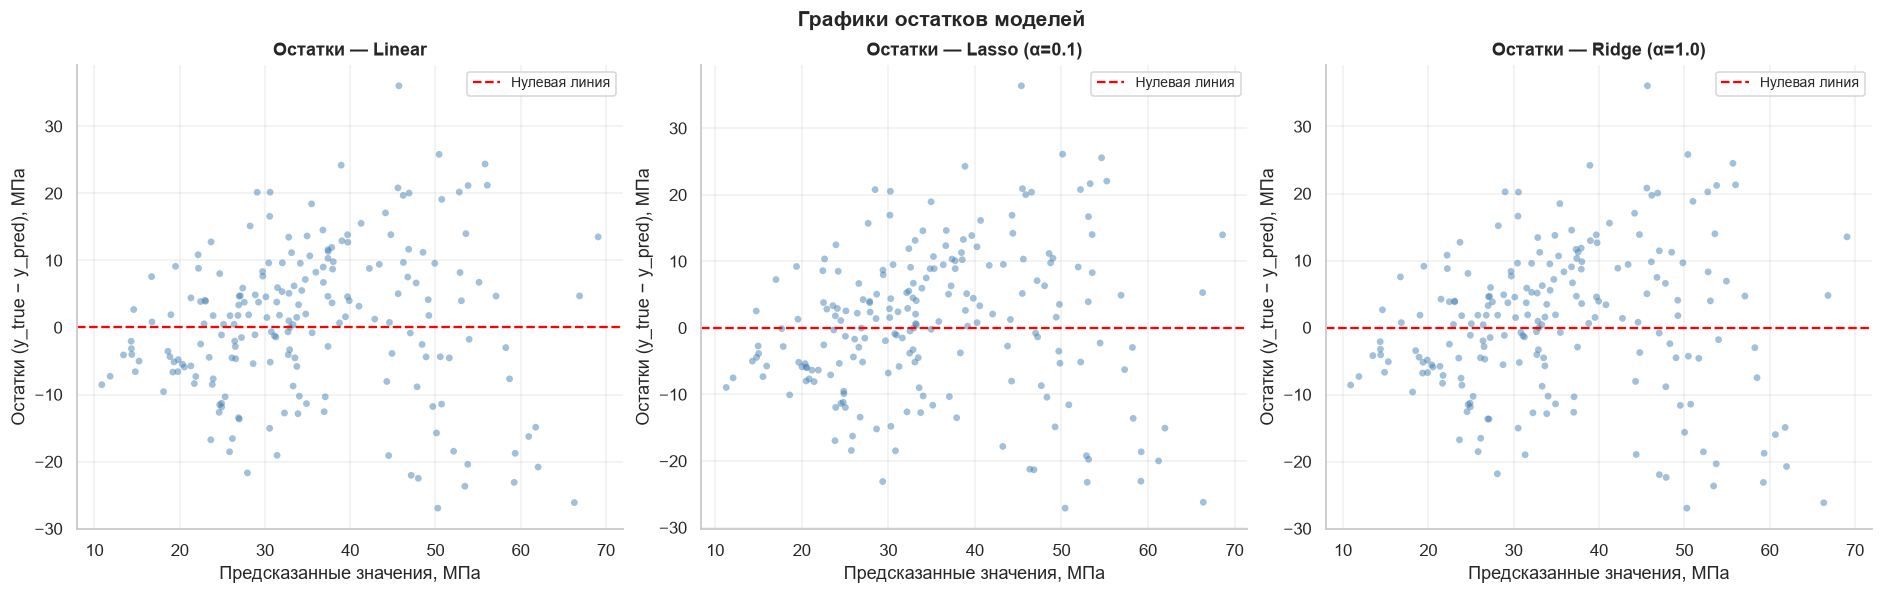

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)

for ax, (name, res) in zip(axes, residuals.items()):
    y_pred = predictions_original[name]
    ax.scatter(y_pred, res, alpha=0.5, s=20, color='steelblue',
               edgecolor='none')
    ax.axhline(0, color='red', linestyle='--', linewidth=1.5,
               label='Нулевая линия')
    ax.set_title(f'Остатки — {name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Предсказанные значения, МПа')
    ax.set_ylabel('Остатки (y_true − y_pred), МПа')
    ax.grid(alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.legend(loc='upper right', fontsize=9)

plt.suptitle('Графики остатков моделей',
             fontsize=14, fontweight='bold', y=1.05)
plt.show()

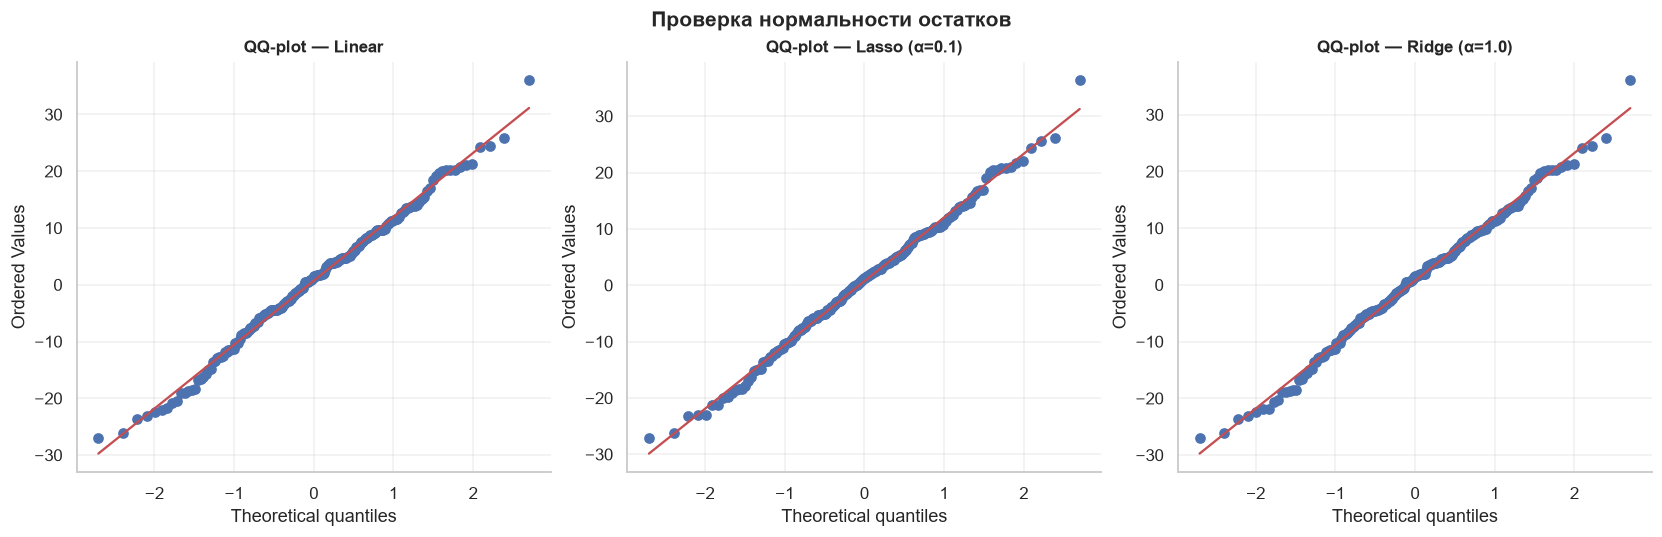

In [33]:
from scipy import stats

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)

for ax, (name, res) in zip(axes, residuals.items()):
    stats.probplot(res, dist="norm", plot=ax)
    ax.set_title(f'QQ-plot — {name}', fontsize=11, fontweight='bold')
    ax.grid(alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle('Проверка нормальности остатков',
             fontsize=14, fontweight='bold', y=1.05)
plt.show()

In [55]:
from statsmodels.stats.diagnostic import het_breuschpagan
import statsmodels.api as sm

print("=== Тест Бройша–Пагана на гетероскедастичность ===\n")
print("H0: гомоскедастичность (дисперсия остатков постоянна)")
print("H1: гетероскедастичность (дисперсия меняется)\n")

for name, res in residuals.items():
    # Берём X_test (стандартизированный), добавляем константу
    X_test_const = sm.add_constant(X_test_sc)
    lm, lm_pvalue, fvalue, f_pvalue = het_breuschpagan(res, X_test_const)

    verdict = "ГЕТЕРОскедастичность " if lm_pvalue < 0.05 else "гомоскедастичность"
    print(f"{name}:")
    print(f"  LM-статистика: {lm:.3f}")
    print(f"  p-value:       {lm_pvalue:.5f}")
    print(f"  Вывод: {verdict}\n")

=== Тест Бройша–Пагана на гетероскедастичность ===

H0: гомоскедастичность (дисперсия остатков постоянна)
H1: гетероскедастичность (дисперсия меняется)

Linear:
  LM-статистика: 50.525
  p-value:       0.00000
  Вывод: ГЕТЕРОскедастичность 

Lasso (α=0.1):
  LM-статистика: 48.605
  p-value:       0.00000
  Вывод: ГЕТЕРОскедастичность 

Ridge (α=1.0):
  LM-статистика: 50.335
  p-value:       0.00000
  Вывод: ГЕТЕРОскедастичность 



# Анализ остатков

Среднее остатков для всех трёх моделей ≈ 0.7 (близко к нулю) — модель несмещённая. 
Стандартное отклонение остатков ≈ 11.2 МПа, что совпадает с RMSE. 
Асимметрия остатков близка к нулю (|skew| < 0.05) — распределение симметричное.

QQ-plot показывает, что остатки близки к нормальному распределению, 
за исключением 1–2 выбросов в правом хвосте.

Тест Бройша–Пагана: p-value < 0.001 для всех трёх моделей → 
обнаружена гетероскедастичность. Дисперсия остатков не постоянна — 
разброс больше при низких и высоких предсказанных значениях, 
меньше в среднем диапазоне. Это типично для неоднородных технических данных 
и является ограничением линейных моделей.

# Метод главных компонент

## Пункт 7. Устранение мультиколлинеарности и снижение размерности с помощью PCA

### 7.1. Выбор числа главных компонент
### 7.2. Обучение PCA и интерпретация нагрузок
### 7.3. Построение моделей на главных компонентах
### 7.4. Сравнение коэффициентов PCA-моделей
### 7.5. Выводы по PCA

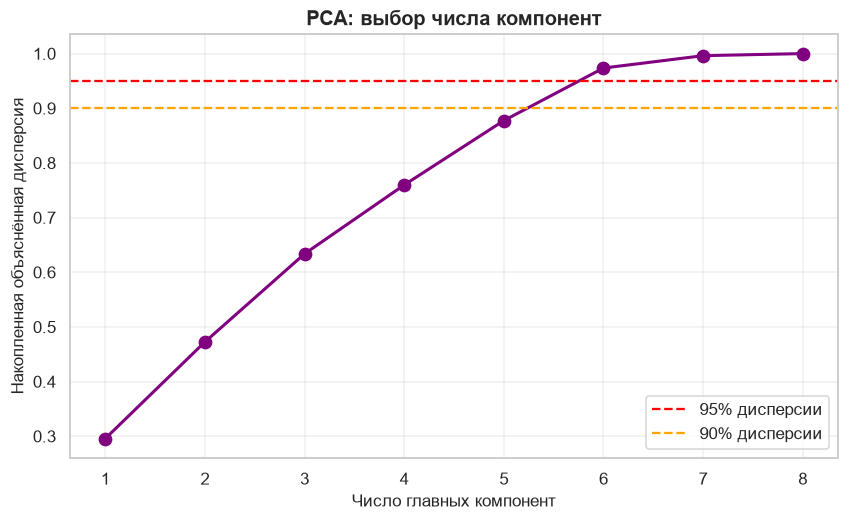

Объяснённая дисперсия по компонентам:
  PC1: 0.2957 (29.57%)  |  накопленная: 0.2957
  PC2: 0.1768 (17.68%)  |  накопленная: 0.4725
  PC3: 0.1612 (16.12%)  |  накопленная: 0.6337
  PC4: 0.1260 (12.60%)  |  накопленная: 0.7597
  PC5: 0.1178 (11.78%)  |  накопленная: 0.8774
  PC6: 0.0961 (9.61%)  |  накопленная: 0.9735
  PC7: 0.0226 (2.26%)  |  накопленная: 0.9962
  PC8: 0.0038 (0.38%)  |  накопленная: 1.0000

Для 90% дисперсии нужно компонент: 6
Для 95% дисперсии нужно компонент: 6


In [39]:
from sklearn.decomposition import PCA


pca_full = PCA().fit(X_train_sc)

cum_var = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(9, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o',
         color='purple', linewidth=2, markersize=8)
plt.axhline(0.95, color='red', linestyle='--', linewidth=1.5,
            label='95% дисперсии')
plt.axhline(0.90, color='orange', linestyle='--', linewidth=1.5,
            label='90% дисперсии')
plt.xlabel('Число главных компонент', fontsize=11)
plt.ylabel('Накопленная объяснённая дисперсия', fontsize=11)
plt.title('PCA: выбор числа компонент', fontsize=13, fontweight='bold')
plt.grid(alpha=0.3)
plt.legend()
plt.xticks(range(1, len(cum_var) + 1))
plt.show()

print("Объяснённая дисперсия по компонентам:")
for i, (var, cum) in enumerate(zip(pca_full.explained_variance_ratio_, cum_var), 1):
    print(f"  PC{i}: {var:.4f} ({var*100:.2f}%)  |  накопленная: {cum:.4f}")

n_comp_95 = np.argmax(cum_var >= 0.95) + 1
n_comp_90 = np.argmax(cum_var >= 0.90) + 1
print(f"\nДля 90% дисперсии нужно компонент: {n_comp_90}")
print(f"Для 95% дисперсии нужно компонент: {n_comp_95}")

In [40]:
pca = PCA(n_components=n_comp_95, random_state=42)

X_train_pca = pca.fit_transform(X_train_sc)
X_test_pca  = pca.transform(X_test_sc)

print(f"Использовано компонент: {n_comp_95}")
print(f"Форма X_train_pca: {X_train_pca.shape}")
print(f"Форма X_test_pca:  {X_test_pca.shape}")
print(f"Сохранено дисперсии: {pca.explained_variance_ratio_.sum()*100:.2f}%")

loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f'PC{i+1}' for i in range(n_comp_95)],
    index=X.columns
)
print("\nВклад признаков в главные компоненты (loadings):")
print(loadings.round(3).to_string())

Использовано компонент: 6
Форма X_train_pca: (804, 6)
Форма X_test_pca:  (201, 6)
Сохранено дисперсии: 97.35%

Вклад признаков в главные компоненты (loadings):
                      PC1    PC2    PC3    PC4    PC5    PC6
cement              0.147 -0.382  0.721 -0.107 -0.128 -0.198
blast_furnace_slag  0.189  0.694 -0.006 -0.368 -0.124  0.297
fly_ash            -0.416  0.015 -0.330  0.449 -0.431 -0.236
water               0.533  0.120 -0.155  0.328  0.068 -0.378
superplasticizer   -0.482  0.195  0.367  0.034 -0.361  0.160
coarse_aggregate    0.014 -0.548 -0.449 -0.444 -0.200  0.291
fine_aggregate     -0.409 -0.022  0.016  0.117  0.774  0.157
age                 0.291 -0.137  0.105  0.576 -0.096  0.734


In [42]:
models_pca = {
    'Linear (PCA)': LinearRegression(),
    'Lasso (PCA)':  Lasso(alpha=0.1, max_iter=10000, random_state=42),
    'Ridge (PCA)':  Ridge(alpha=1.0, random_state=42),
}

predictions_pca = {}
results_pca = []

for name, model in models_pca.items():
    y_pred, metrics = evaluate_model(
        model, X_train_pca, y_train, X_test_pca, y_test, name)
    predictions_pca[name] = y_pred
    results_pca.append(metrics)

─── Linear (PCA) ───
CV RMSE:   10.786 ± 0.223
Test RMSE: 11.946
Test R²:   0.5216
Test MAPE: 37.17%

─── Lasso (PCA) ───
CV RMSE:   10.781 ± 0.214
Test RMSE: 11.961
Test R²:   0.5204
Test MAPE: 37.57%

─── Ridge (PCA) ───
CV RMSE:   10.786 ± 0.222
Test RMSE: 11.947
Test R²:   0.5215
Test MAPE: 37.19%



In [43]:
lin_pca = LinearRegression().fit(X_train_pca, y_train)
las_pca = Lasso(alpha=0.1, max_iter=10000, random_state=42).fit(X_train_pca, y_train)
rid_pca = Ridge(alpha=1.0, random_state=42).fit(X_train_pca, y_train)

coef_pca_df = pd.DataFrame({
    'Компонента': [f'PC{i+1}' for i in range(n_comp_95)],
    'Linear': lin_pca.coef_,
    'Lasso':  las_pca.coef_,
    'Ridge':  rid_pca.coef_,
})

print("Коэффициенты моделей на главных компонентах:")
print(coef_pca_df.round(3).to_string(index=False))

lasso_pca_zeros = coef_pca_df[coef_pca_df['Lasso'] == 0]['Компонента'].tolist()
print(f"\nLasso обнулил компоненты: {lasso_pca_zeros if lasso_pca_zeros else 'ничего'}")

Коэффициенты моделей на главных компонентах:
Компонента  Linear  Lasso  Ridge
       PC1  -0.016 -0.000 -0.016
       PC2  -0.276 -0.206 -0.276
       PC3   8.266  8.189  8.258
       PC4   0.813  0.714  0.812
       PC5  -5.457 -5.351 -5.450
       PC6   5.882  5.752  5.872

Lasso обнулил компоненты: ['PC1']


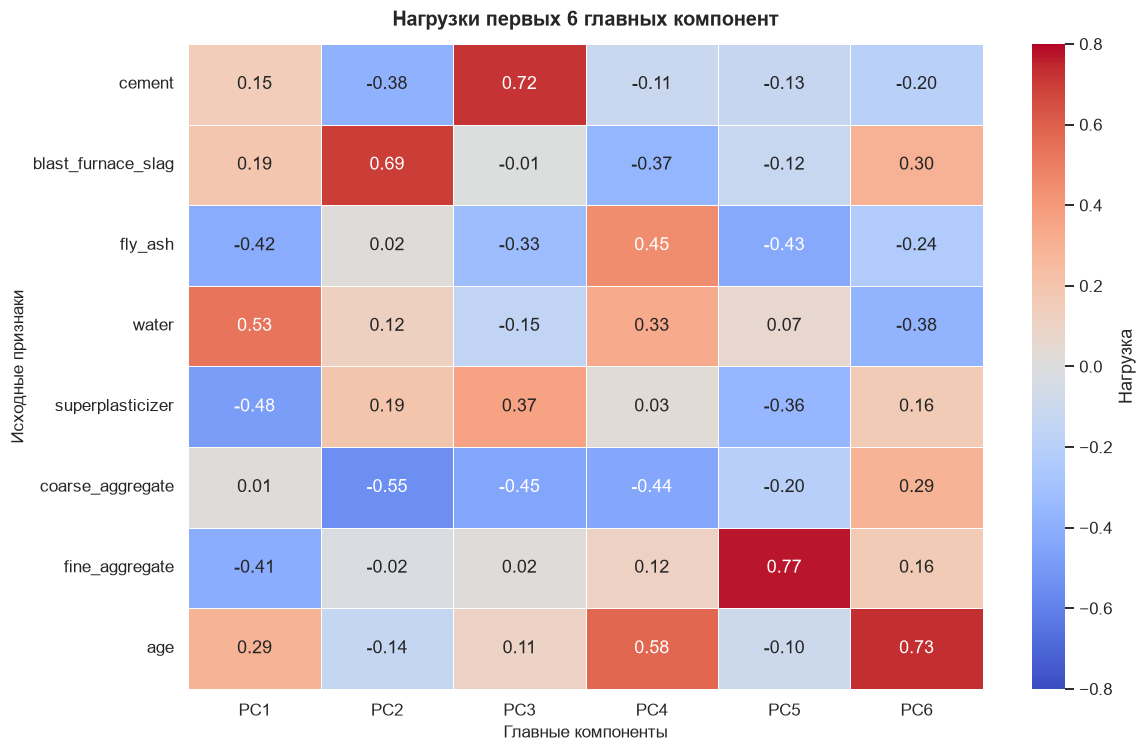

In [53]:
plt.figure(figsize=(11, 7))
sns.heatmap(
    loadings,
    annot=True, fmt='.2f', cmap='coolwarm', center=0,
    vmin=-0.8, vmax=0.8, linewidths=0.5,
    cbar_kws={'label': 'Нагрузка'}
)
plt.title('Нагрузки первых 6 главных компонент',
          fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Главные компоненты', fontsize=11)
plt.ylabel('Исходные признаки', fontsize=11)
plt.tight_layout()
plt.show()

# Выводы по PCA

По правилу Кайзера (собственное значение > 1, т.е. объяснённая дисперсия > 12.5%) 
следует оставить 4 компоненты, однако они сохраняют только 75.97% общей дисперсии.

Для дальнейшего регрессионного анализа выбраны 6 компонент, поскольку они позволяют 
сохранить 97.35% дисперсии при уменьшении размерности с 8 до 6 признаков.

### Интерпретация главных компонент

- **PC1 (29.6%)** — «водно-добавочная ось»: `water` (+) против `superplasticizer` (−) 
  и `fly_ash` (−). Отражает баланс между водой и добавками-пластификаторами.
- **PC2 (17.7%)** — «вяжущие vs заполнители»: `blast_furnace_slag` (+) против 
  `coarse_aggregate` (−).
- **PC3 (16.1%)** — «цемент vs крупный заполнитель»: `cement` (+) против `coarse_aggregate` (−). 
  Самая важная для предсказания компонента.
- **PC4 (12.6%)** — «возраст + зола-унос».
- **PC5 (11.8%)** — «тонкие фракции» (`fine_aggregate`).
- **PC6 (9.6%)** — «возраст» (доминирует `age`).

Все компоненты ортогональны — мультиколлинеарность устранена.

## Пункт 8. Сравнение моделей на исходных данных и на главных компонентах

### 8.1. Сводная таблица метрик
### 8.2. Визуальное сравнение метрик
### 8.3. Заключение


In [44]:
all_results = results_original + results_pca
comparison = pd.DataFrame(all_results)

comparison['Данные'] = ['Исходные'] * 3 + ['PCA'] * 3

comparison = comparison[['Данные', 'Модель', 'CV RMSE', 'RMSE', 'R²', 'MAPE, %']]

print("=" * 80)
print("СРАВНЕНИЕ МЕТРИК: ИСХОДНЫЕ ДАННЫЕ vs PCA")
print("=" * 80)
print(comparison.round(4).to_string(index=False))

СРАВНЕНИЕ МЕТРИК: ИСХОДНЫЕ ДАННЫЕ vs PCA
  Данные        Модель  CV RMSE    RMSE     R²  MAPE, %
Исходные        Linear  10.2019 11.1913 0.5802  34.6852
Исходные Lasso (α=0.1)  10.2033 11.2295 0.5773  35.1338
Исходные Ridge (α=1.0)  10.2018 11.1934 0.5800  34.7268
     PCA  Linear (PCA)  10.7865 11.9462 0.5216  37.1657
     PCA   Lasso (PCA)  10.7814 11.9613 0.5204  37.5742
     PCA   Ridge (PCA)  10.7861 11.9471 0.5215  37.1879


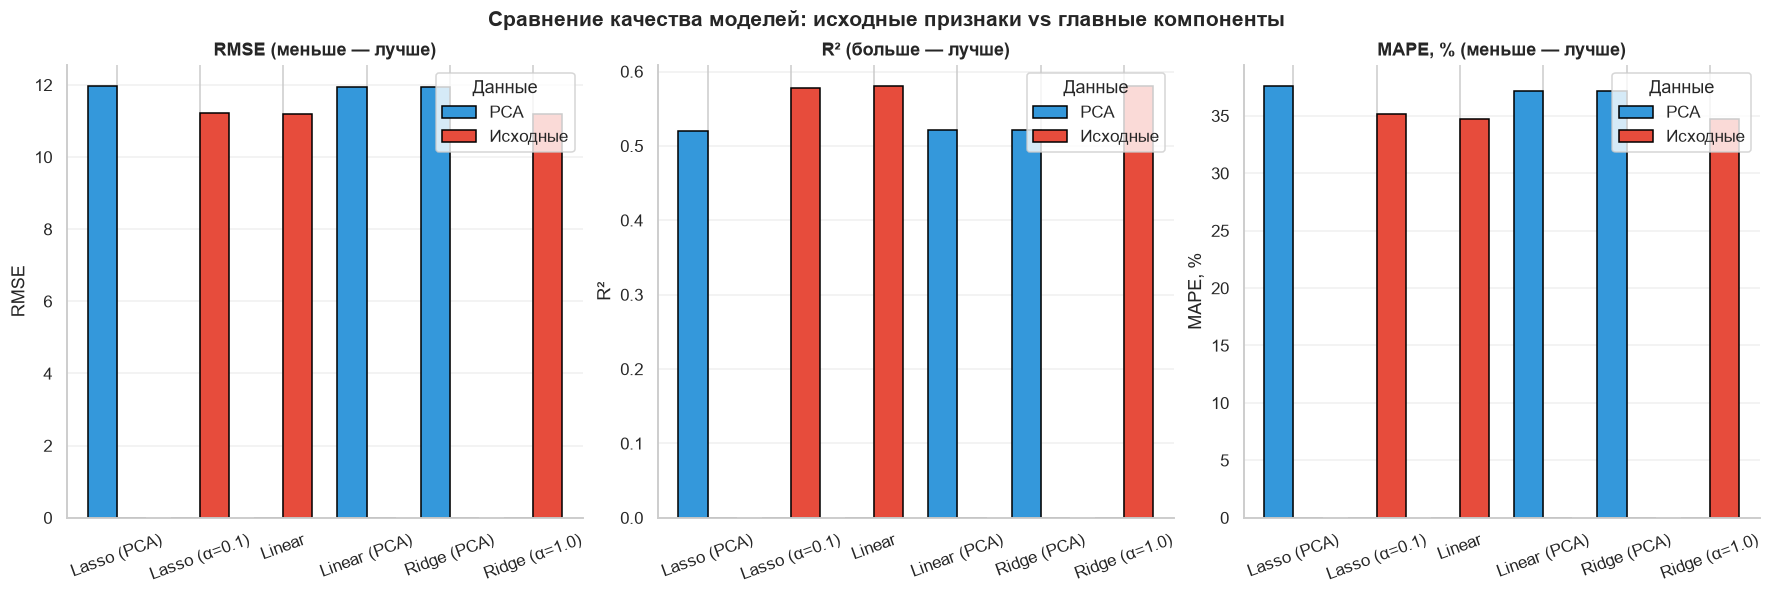

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)

metrics = ['RMSE', 'R²', 'MAPE, %']
titles = ['RMSE (меньше — лучше)', 'R² (больше — лучше)', 'MAPE, % (меньше — лучше)']

for ax, metric, title in zip(axes, metrics, titles):
    data = comparison.pivot(index='Модель', columns='Данные', values=metric)
    data.plot(kind='bar', ax=ax, color=['#3498db', '#e74c3c'],
              edgecolor='black', width=0.7)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=20)
    ax.grid(axis='y', alpha=0.3)
    ax.set_axisbelow(True)
    ax.legend(title='Данные', loc='best')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle('Сравнение качества моделей: исходные признаки vs главные компоненты',
             fontsize=14, fontweight='bold', y=1.05)
plt.show()

# Заключение

В результате исследования было установлено, что применение PCA привело к **снижению** 
качества регрессионных моделей. При сокращении размерности с 8 исходных признаков 
до 6 главных компонент удалось сохранить **97.35%** общей дисперсии признакового пространства.

Для линейной регрессии RMSE **увеличился** с 11.191 до 11.946 МПа, 
а R² **уменьшился** с 0.5802 до 0.5216. MAPE также вырос с 34.69% до 37.17%. 
Модели Lasso и Ridge на главных компонентах показали аналогичное ухудшение.

Снижение качества объясняется тем, что мультиколлинеарность в датасете была 
**умеренной** (VIF 5–10 у 5 из 8 признаков), а PCA максимизирует дисперсию, 
а не предсказательную силу. При выкидывании PC7 и PC8 (вместе 2.6% дисперсии) 
теряется часть полезного для предсказания сигнала.

Таким образом, **PCA оправдал себя как метод снижения размерности** (8 → 6 признаков, 
−25% без существенной потери информации), однако **существенного улучшения 
прогнозного качества не дал**. В условиях умеренной мультиколлинеарности и небольшого 
числа признаков **модели на исходных данных оказались предпочтительнее**. 
PCA целесообразно применять при большем числе сильно коррелированных признаков 
(VIF > 20–30).